## 01 · K-Means 군집화
교재 **173쪽**

In [1]:
# 필요한 라이브러리를 불러옵니다.
import pandas as pd
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt

# 데이터를 불러옵니다. (Part4 Chapter9 Mall Customers.csv 파일이 코드와 같은 폴더에 있어야 합니다)
df = pd.read_csv("Part4 Chapter9 Mall Customers.csv")

# 군집화에 사용할 피처를 선택합니다.
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]

# KMeans 모델을 생성하고 학습시킵니다. (5개의 그룹으로 설정)
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans.fit(X)

# 각 데이터가 어떤 클러스터에 속하는지 결과를 데이터프레임에 추가합니다.
df['cluster'] = kmeans.labels_

# 결과 상위 5개를 확인합니다.
print(df.head())

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   cluster  
0        4  
1        2  
2        4  
3        2  
4        4  


## 02 · K-Means 군집 시각화
교재 **174–175쪽**

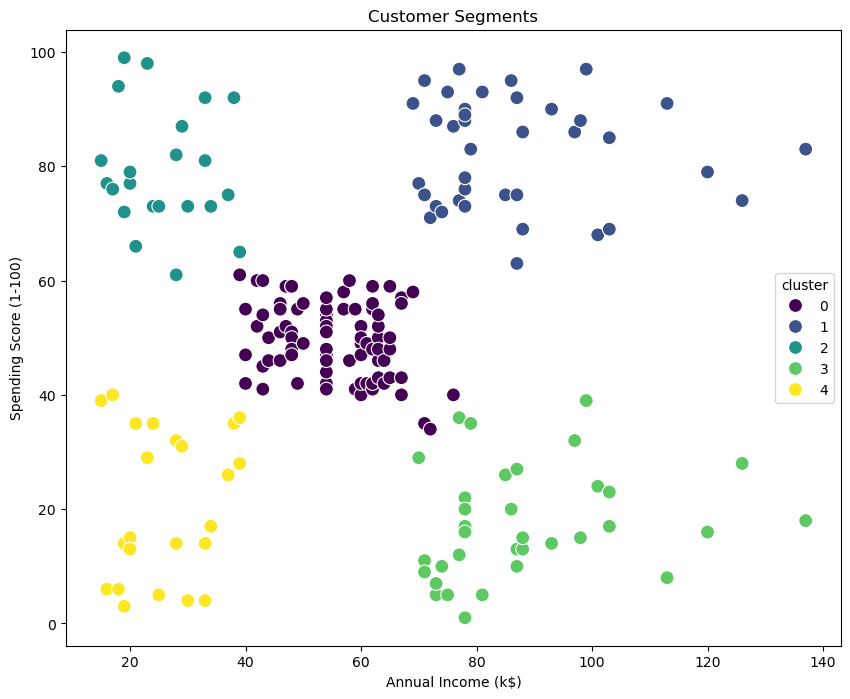

In [2]:
# 그래프의 크기를 설정합니다.
plt.figure(figsize=(10, 8))

# scatterplot을 사용하여 군집화 결과를 시각화합니다.
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', hue='cluster', 
data=df, palette='viridis', s=100)

# 그래프에 제목을 추가합니다.
plt.title('Customer Segments')
plt.show()

## 03 · PCA 차원 축소
교재 **176–177쪽**

In [3]:
# 필요한 라이브러리를 불러옵니다.
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 데이터를 불러옵니다. (Mall_Customers.csv 파일이 코드와 같은 폴더에 있어야 합니다)
df = pd.read_csv("Part4 Chapter9 Mall Customers.csv")

# 차원 축소에 사용할 피처를 선택합니다.
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]

# 1. 데이터 스케일링 (StandardScaler 사용)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. PCA 모델 생성 및 학습 (2개의 주성분으로 축소)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 3. 결과를 새로운 데이터프레임으로 만듭니다.
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])

# 결과 상위 5개를 확인합니다.
print(pca_df.head())

        PC1       PC2
0 -0.615720 -1.763481
1 -1.665793 -1.820747
2  0.337862 -1.674799
3 -1.456573 -1.772430
4 -0.038465 -1.662740


## 04 · PCA 결과 시각화
교재 **177–178쪽**

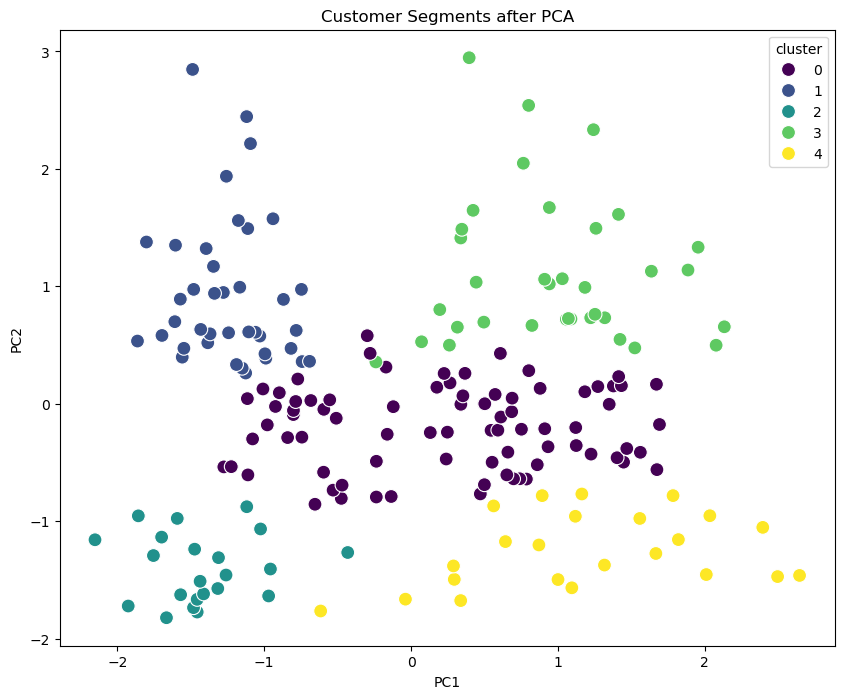

In [4]:
df['cluster'] = kmeans.labels_

# PCA 결과를 담은 데이터프레임에 클러스터 정보를 추가합니다.
pca_df['cluster'] = df['cluster']

# 그래프의 크기를 설정합니다.
plt.figure(figsize=(10, 8))

# scatterplot을 사용하여 차원 축소 결과를 시각화합니다.
sns.scatterplot(x='PC1', y='PC2', hue='cluster', data=pca_df, palette='viridis', 
s=100)

# 그래프에 제목을 추가합니다.
plt.title('Customer Segments after PCA')
plt.show()

## 05 · DBSCAN 군집화
교재 **179쪽**

In [5]:
# 필요한 라이브러리를 불러옵니다.
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 데이터를 불러옵니다. (Part4 Chapter9 Mall Customers.csv 파일이 코드와 같은 폴더에 있어야 합니다)
df = pd.read_csv("Part4 Chapter9 Mall Customers.csv")

# 군집화에 사용할 피처를 선택하고 스케일링합니다.
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# DBSCAN 모델을 생성하고 학습시킵니다.
dbscan = DBSCAN(eps=0.5, min_samples=5)
clusters = dbscan.fit_predict(X_scaled)

# DBSCAN 결과를 데이터프레임에 추가합니다.
df['dbscan_cluster'] = clusters

# 클러스터별 데이터 개수를 확인합니다.
print(df['dbscan_cluster'].value_counts())

dbscan_cluster
 0    157
 1     35
-1      8
Name: count, dtype: int64


## 06 · DBSCAN 군집 시각화
교재 **180쪽**

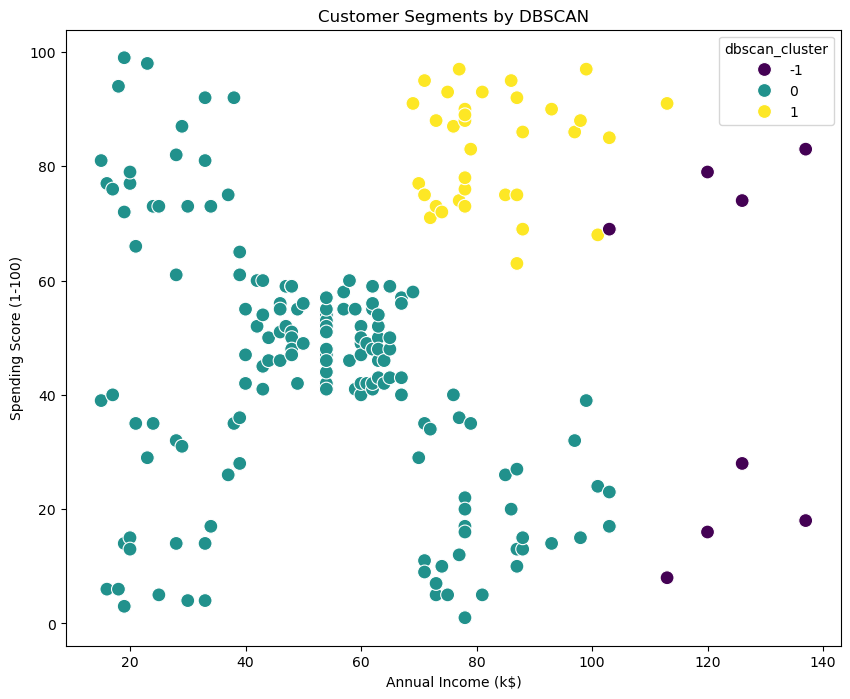

In [6]:
# 그래프의 크기를 설정합니다.
plt.figure(figsize=(10, 8))

# scatterplot을 사용하여 DBSCAN 군집화 결과를 시각화합니다.
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', hue='dbscan_cluster',
data=df, palette='viridis', s=100)

# 그래프에 제목을 추가합니다.
plt.title('Customer Segments by DBSCAN')
plt.show()